<a href="https://colab.research.google.com/github/SabAneesah/Enhancing-Performance-with-Federated-SLMs/blob/main/dataset/Dataset_Visualization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install datasets matplotlib seaborn wordcloud pandas

In [2]:
from datasets import load_dataset
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud

# 1. User's Data Loading Logic
dataset = load_dataset("wikitext", "wikitext-2-raw-v1", split="train")
dataset = dataset.select(range(10000))
dataset = dataset.filter(lambda x: len(x["text"]) > 10)   # filter empty lines
partition_size = len(dataset) // 5  # Assuming 5 clients

print(f"Total valid samples: {len(dataset)}")
print(f"Samples per client: {partition_size}")

# 2. Convert to Pandas DataFrame
df = pd.DataFrame(dataset)

# 3. Extract metadata for visualization
df['char_length'] = df['text'].apply(len)
df['word_count'] = df['text'].apply(lambda x: len(x.split()))

# 4. Assign simulated Client IDs based on your partition size
# (The min function ensures any remainder goes to the last client)
df['client_id'] = [min(i // partition_size, 4) for i in range(len(df))]
df.head()

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md: 0.00B [00:00, ?B/s]

wikitext-2-raw-v1/test-00000-of-00001.pa(…):   0%|          | 0.00/733k [00:00<?, ?B/s]

wikitext-2-raw-v1/train-00000-of-00001.p(…):   0%|          | 0.00/6.36M [00:00<?, ?B/s]

wikitext-2-raw-v1/validation-00000-of-00(…):   0%|          | 0.00/657k [00:00<?, ?B/s]

Generating test split:   0%|          | 0/4358 [00:00<?, ? examples/s]

Generating train split:   0%|          | 0/36718 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/3760 [00:00<?, ? examples/s]

Filter:   0%|          | 0/10000 [00:00<?, ? examples/s]

Total valid samples: 6479
Samples per client: 1295


,text,char_length,word_count,client_id
0,= Valkyria Chronicles III = \n,30,5,0
1,Senjō no Valkyria 3 : Unrecorded Chronicles (...,706,127,0
2,"The game began development in 2010 , carrying...",524,91,0
3,"It met with positive sales in Japan , and was...",574,101,0
4,= = Gameplay = = \n,19,5,0


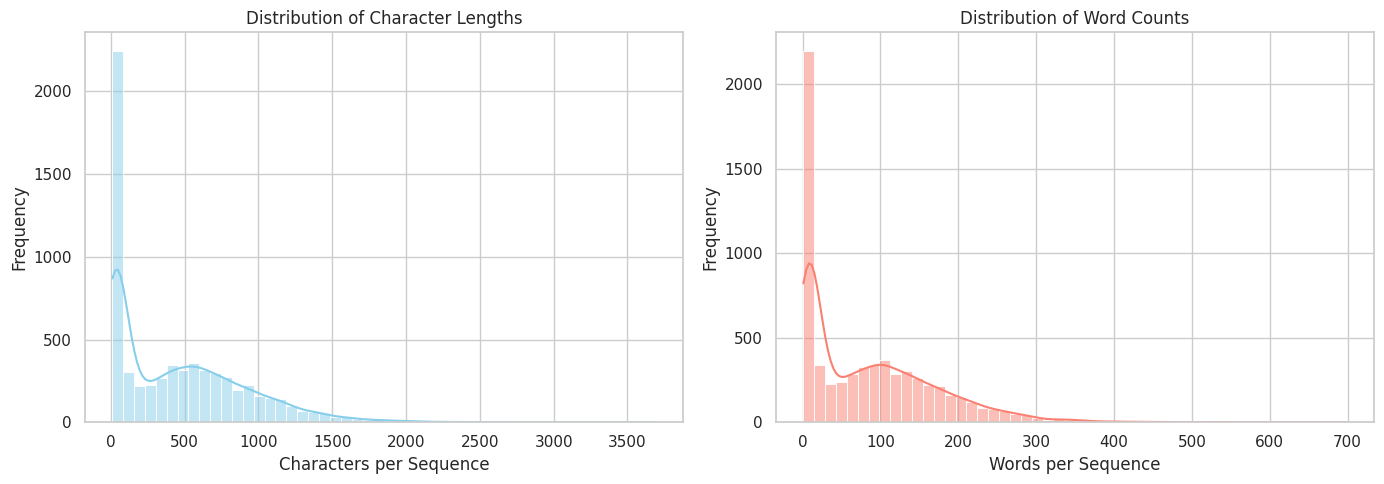

In [3]:
# Set the visual style
sns.set_theme(style="whitegrid")
plt.figure(figsize=(14, 5))

# Plot 1: Character Lengths
plt.subplot(1, 2, 1)
sns.histplot(df['char_length'], bins=50, kde=True, color='skyblue')
plt.title('Distribution of Character Lengths')
plt.xlabel('Characters per Sequence')
plt.ylabel('Frequency')

# Plot 2: Word Counts
plt.subplot(1, 2, 2)
sns.histplot(df['word_count'], bins=50, kde=True, color='salmon')
plt.title('Distribution of Word Counts')
plt.xlabel('Words per Sequence')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

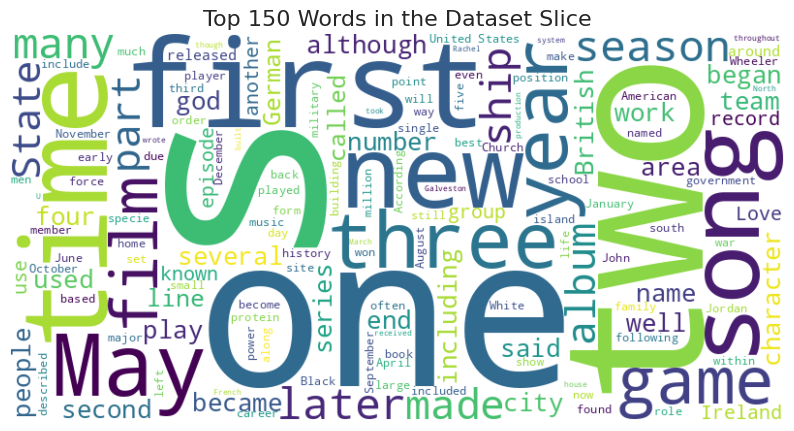

In [4]:
plt.figure(figsize=(10, 6))

# Combine all text into one massive string
text_corpus = " ".join(df['text'].tolist())

# Generate the word cloud
wordcloud = WordCloud(
    width=800,
    height=400,
    background_color='white',
    colormap='viridis',
    max_words=150
).generate(text_corpus)

plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Top 150 Words in the Dataset Slice', fontsize=16)
plt.show()

/tmp/ipykernel_6172/3959613281.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='client_id', y='word_count', data=df, palette='Set2')


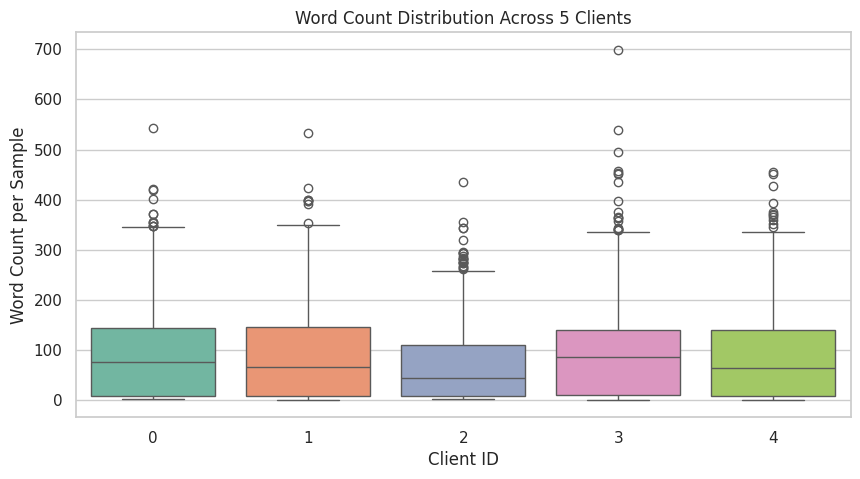

In [5]:
plt.figure(figsize=(10, 5))

# Boxplot to show the spread of word counts across the 5 clients
sns.boxplot(x='client_id', y='word_count', data=df, palette='Set2')
plt.title('Word Count Distribution Across 5 Clients')
plt.xlabel('Client ID')
plt.ylabel('Word Count per Sample')

plt.show()

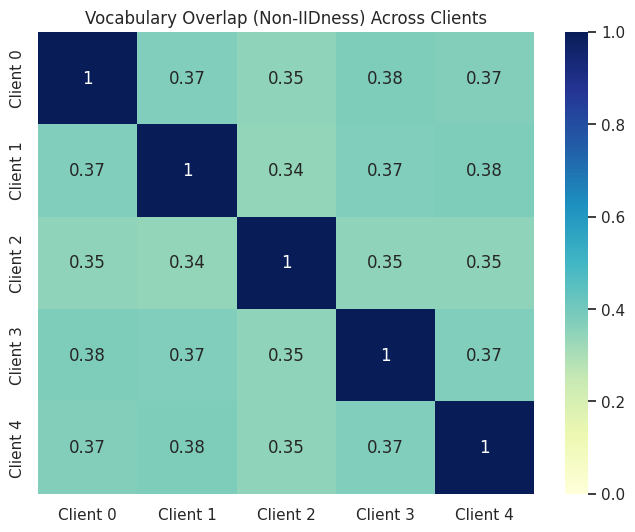

In [6]:
# The Non-IID Proof: Vocabulary Overlap Heatmap
import numpy as np
from sklearn.feature_extraction.text import CountVectorizer

plt.figure(figsize=(8, 6))

# 1. Extract the top 1000 words for each client to represent their "domain"
client_vocab = {}
vectorizer = CountVectorizer(max_features=1000, stop_words='english')

for client in range(5):
    client_text = df[df['client_id'] == client]['text'].tolist()
    # Fit vectorizer to get the top words for this specific client
    vectorizer.fit(client_text)
    client_vocab[client] = set(vectorizer.get_feature_names_out())

# 2. Calculate Jaccard Similarity between all client pairs
# Jaccard = (Intersection of words) / (Union of words)
similarity_matrix = np.zeros((5, 5))
for i in range(5):
    for j in range(5):
        intersection = len(client_vocab[i].intersection(client_vocab[j]))
        union = len(client_vocab[i].union(client_vocab[j]))
        similarity_matrix[i, j] = intersection / union if union != 0 else 0

# 3. Plot the Heatmap
sns.heatmap(similarity_matrix, annot=True, cmap="YlGnBu", vmin=0, vmax=1,
            xticklabels=[f"Client {i}" for i in range(5)],
            yticklabels=[f"Client {i}" for i in range(5)])

plt.title("Vocabulary Overlap (Non-IIDness) Across Clients")
plt.show()

/tmp/ipykernel_6172/575715232.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='client_id', y='ttr', data=df, palette='muted', inner="quartile")


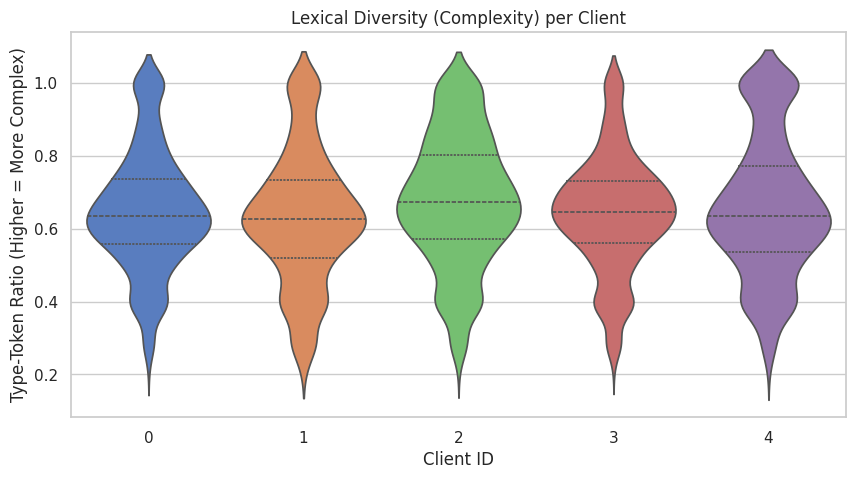

In [7]:
# The SLM Capacity Check: Lexical Diversity (Type-Token Ratio)
plt.figure(figsize=(10, 5))

# 1. Calculate Type-Token Ratio (TTR) for each text sequence
def calculate_ttr(text):
    words = text.split()
    if len(words) == 0:
        return 0
    return len(set(words)) / len(words)

df['ttr'] = df['text'].apply(calculate_ttr)

# 2. Visualize the complexity per client using a Violin Plot
sns.violinplot(x='client_id', y='ttr', data=df, palette='muted', inner="quartile")

plt.title("Lexical Diversity (Complexity) per Client")
plt.xlabel("Client ID")
plt.ylabel("Type-Token Ratio (Higher = More Complex)")
plt.show()

/tmp/ipykernel_6172/72451808.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(x='word_count', y='client_id', data=df,


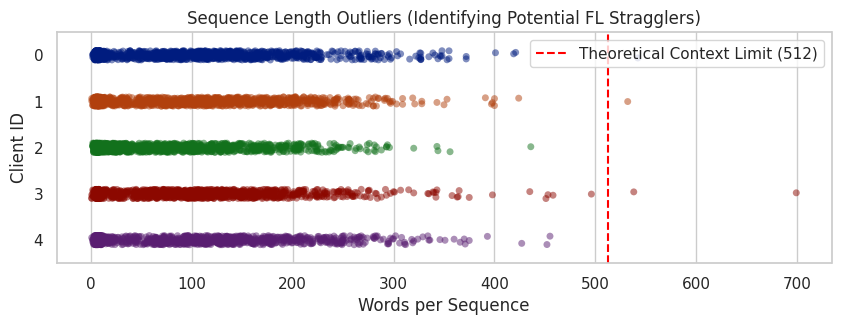

In [8]:
# The Straggler Effect: Outlier Analysis for Context Windows
plt.figure(figsize=(10, 3))

# Using a scatter plot/stripplot to clearly see extreme outliers
sns.stripplot(x='word_count', y='client_id', data=df,
              orient='h', alpha=0.5, jitter=True, palette='dark')

# Add a vertical line simulating a typical SLM context window cutoff
# (e.g., 512 tokens - using words as a rough proxy)
plt.axvline(x=512, color='red', linestyle='--', label='Theoretical Context Limit (512)')

plt.title("Sequence Length Outliers (Identifying Potential FL Stragglers)")
plt.xlabel("Words per Sequence")
plt.ylabel("Client ID")
plt.legend()
plt.show()

DIRICHLET DISTRIBUTION

In [15]:
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import MiniBatchKMeans

# --- Configuration for your experiment ---
NUM_CLIENTS = 5
NUM_TOPICS = 5      # Number of distinct "themes" to discover in Wikitext
ALPHA = 1.0        # Your skew dial: 0.1 (Extreme skew), 1.0 (Moderate), 10.0 (Uniform)

print(f"Setting up Dirichlet partition with Alpha = {ALPHA}...\n")

# 1. Discover Topics (Pseudo-labels) using TF-IDF
vectorizer = TfidfVectorizer(max_features=1000, stop_words='english')
X_tfidf = vectorizer.fit_transform(df['text'])

# Fast clustering to assign a topic (0-4) to every text sequence
kmeans = MiniBatchKMeans(n_clusters=NUM_TOPICS, random_state=42, n_init="auto")
df['topic_label'] = kmeans.fit_predict(X_tfidf)
print("Finished grouping data into topics.")

# 2. Prepare the Dirichlet Distribution Logic
client_indices = {i: [] for i in range(NUM_CLIENTS)}

# For reproducibility in your research
np.random.seed(42)

for topic in range(NUM_TOPICS):
    # Get all row indices belonging to this specific topic
    topic_indices = df[df['topic_label'] == topic].index.tolist()
    np.random.shuffle(topic_indices)

    # Draw proportions for this topic across all 5 clients using the Dirichlet distribution
    proportions = np.random.dirichlet(np.repeat(ALPHA, NUM_CLIENTS))

    # Convert those probability proportions into actual row counts
    splits = (proportions * len(topic_indices)).astype(int)

    # Catch any rounding remainders and assign them to the last client
    splits[-1] = len(topic_indices) - splits[:-1].sum()

    # Distribute the actual data indices to the clients based on the splits
    start_idx = 0
    for client in range(NUM_CLIENTS):
        end_idx = start_idx + splits[client]
        client_indices[client].extend(topic_indices[start_idx:end_idx])
        start_idx = end_idx

# 3. Map the new assignments back to your DataFrame
df['dirichlet_client_id'] = -1
for client, indices in client_indices.items():
    df.loc[indices, 'dirichlet_client_id'] = int(client)

print("Dirichlet partitioning complete!")

Setting up Dirichlet partition with Alpha = 1.0...

Finished grouping data into topics.
Dirichlet partitioning complete!


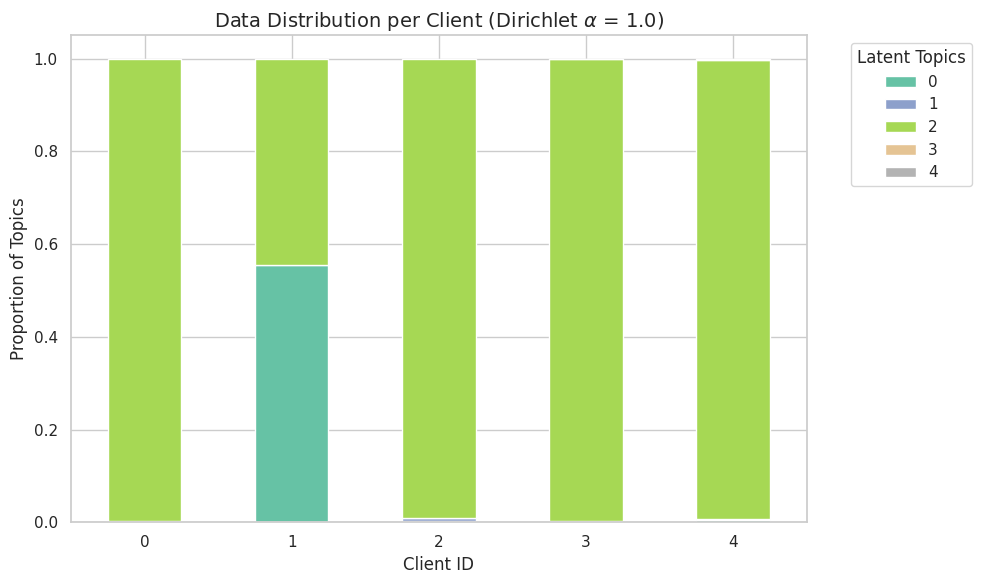

Samples per client under Dirichlet partitioning:
dirichlet_client_id
0     854
1       9
2    1349
3    2401
4    1866
Name: count, dtype: int64


In [16]:
# Create a cross-tabulation of clients vs. topics
distribution_matrix = pd.crosstab(df['dirichlet_client_id'], df['topic_label'], normalize='index')

# Plot the stacked bar chart
ax = distribution_matrix.plot(
    kind='bar',
    stacked=True,
    figsize=(10, 6),
    colormap='Set2',
    edgecolor='white'
)

plt.title(f'Data Distribution per Client (Dirichlet $\\alpha$ = {ALPHA})', fontsize=14)
plt.xlabel('Client ID', fontsize=12)
plt.ylabel('Proportion of Topics', fontsize=12)

# Move legend outside the plot
plt.legend(title='Latent Topics', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Verify data quantities
print("Samples per client under Dirichlet partitioning:")
print(df['dirichlet_client_id'].value_counts().sort_index())